# Exercício 02 – Análise Exploratória (EDA) do dataset Olist

**Objetivo:** entender o dataset de e-commerce da Olist antes de construir o RAG — qualidade dos
dados, valores nulos, relação entre atraso na entrega e nota da avaliação, e quais categorias de
produto geram mais avaliações (e com que nota média).

Datasets usados (baixados via `src/data/download_data.py`, em `data/raw/`):
- `olist_orders_dataset.csv` — pedidos (status, datas de compra/entrega)
- `olist_order_reviews_dataset.csv` — avaliações dos clientes
- `olist_order_items_dataset.csv` — itens de cada pedido (produto vendido)
- `olist_products_dataset.csv` + `product_category_name_translation.csv` — categoria do produto (traduzida para inglês)

> Nota: a limpeza "de produção" (a que alimenta o RAG) vive em `src/data/preprocess.py`.
> Este notebook é só para EDA/prototipação, conforme o `CLAUDE.md` do projeto.

## 1. Carregar os dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (9, 5)

PASTA_DADOS = "../data/raw"

orders = pd.read_csv(f"{PASTA_DADOS}/olist_orders_dataset.csv")
reviews = pd.read_csv(f"{PASTA_DADOS}/olist_order_reviews_dataset.csv")
order_items = pd.read_csv(f"{PASTA_DADOS}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{PASTA_DADOS}/olist_products_dataset.csv")
traducao_categoria = pd.read_csv(f"{PASTA_DADOS}/product_category_name_translation.csv")

for nome, df in [("orders", orders), ("reviews", reviews), ("order_items", order_items), ("products", products)]:
    print(f"{nome}: {df.shape[0]} linhas, {df.shape[1]} colunas")

orders: 99441 linhas, 8 colunas
reviews: 99224 linhas, 7 colunas
order_items: 112650 linhas, 7 colunas
products: 32951 linhas, 9 colunas


## 2. Visão geral e valores nulos

In [2]:
reviews.info()
reviews.head(3)

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


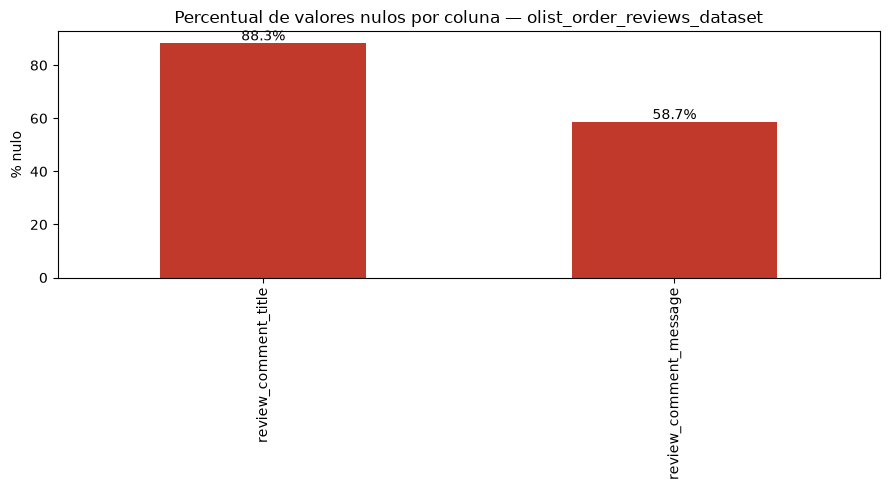

In [3]:
nulos_reviews = reviews.isna().mean().sort_values(ascending=False) * 100
nulos_reviews = nulos_reviews[nulos_reviews > 0]

ax = nulos_reviews.plot(kind="bar", color="#c0392b")
ax.set_title("Percentual de valores nulos por coluna — olist_order_reviews_dataset")
ax.set_ylabel("% nulo")
ax.set_xlabel("")
for i, valor in enumerate(nulos_reviews):
    ax.text(i, valor + 1, f"{valor:.1f}%", ha="center")
plt.tight_layout()
plt.show()

`review_comment_title` é nulo em quase todas as linhas (cliente raramente preenche um título) e
`review_comment_message` é nulo em mais da metade — como o RAG depende de texto, essas linhas sem
comentário não têm o que ser buscado semanticamente e serão descartadas na limpeza.

## 3. Limpeza dos dados

In [4]:
# Datas como datetime (necessário para calcular tempo de entrega/atraso)
colunas_data_orders = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for coluna in colunas_data_orders:
    orders[coluna] = pd.to_datetime(orders[coluna])

reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])

# `review_id` tem duplicatas no dataset original (mesma review ligada a mais de um pedido)
duplicados = reviews["review_id"].duplicated().sum()
print(f"review_id duplicados: {duplicados}")
reviews = reviews.drop_duplicates(subset="review_id", keep="first")

# Só reviews com texto interessam para o RAG (busca semântica precisa de conteúdo)
total_antes = len(reviews)
reviews_com_texto = reviews.dropna(subset=["review_comment_message"]).copy()
reviews_com_texto = reviews_com_texto[reviews_com_texto["review_comment_message"].str.strip() != ""]
print(f"Reviews: {total_antes} -> {len(reviews_com_texto)} após remover sem texto")

# Categoria do produto: um pedido pode ter vários itens: usamos o primeiro item como categoria representativa
item_principal = order_items.drop_duplicates(subset="order_id", keep="first")[["order_id", "product_id"]]
produto_categoria = item_principal.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
produto_categoria = produto_categoria.merge(traducao_categoria, on="product_category_name", how="left")
produto_categoria["product_category_name_english"] = produto_categoria["product_category_name_english"].fillna("nao_informado")
produto_categoria = produto_categoria[["order_id", "product_category_name_english"]]

review_id duplicados: 814
Reviews: 98410 -> 40641 após remover sem texto


## 4. Transformação de variáveis (features derivadas)

Decisão sobre booleanos: só vale transformar em booleano quando a pergunta de negócio é
binária por natureza (ex: "a entrega atrasou?", "a avaliação foi crítica?"). Métricas como
`tempo_entrega_dias` ficam numéricas porque a magnitude importa para os gráficos e para o RAG
poder filtrar por faixas — transformá-las em booleano perderia informação sem necessidade.

In [5]:
base = reviews_com_texto.merge(orders, on="order_id", how="left")
base = base.merge(produto_categoria, on="order_id", how="left")

# Tempo de entrega e atraso só existem para pedidos efetivamente entregues
entregue = base["order_delivered_customer_date"].notna()
base["tempo_entrega_dias"] = (base["order_delivered_customer_date"] - base["order_purchase_timestamp"]).dt.days
base["atraso_dias"] = (base["order_delivered_customer_date"] - base["order_estimated_delivery_date"]).dt.days

# Booleanos: perguntas de sim/não que vamos usar direto nos gráficos e, depois, como metadado de filtro no RAG
base["entrega_atrasada"] = np.where(entregue, base["atraso_dias"] > 0, np.nan)
base["avaliacao_critica"] = base["review_score"] <= 2      # 1-2 estrelas
base["avaliacao_positiva"] = base["review_score"] >= 4     # 4-5 estrelas

print(f"Linhas na base consolidada: {len(base)}")
base[["review_score", "avaliacao_critica", "avaliacao_positiva", "tempo_entrega_dias", "atraso_dias", "entrega_atrasada", "product_category_name_english"]].head()

Linhas na base consolidada: 40641


,review_score,avaliacao_critica,avaliacao_positiva,tempo_entrega_dias,atraso_dias,entrega_atrasada,product_category_name_english
0,5,False,True,10.0,-20.0,0.0,garden_tools
1,5,False,True,18.0,-9.0,0.0,sports_leisure
2,4,False,True,7.0,-16.0,0.0,small_appliances
3,4,False,True,3.0,-11.0,0.0,health_beauty
4,5,False,True,3.0,-16.0,0.0,computers_accessories


## 5. Insights visuais

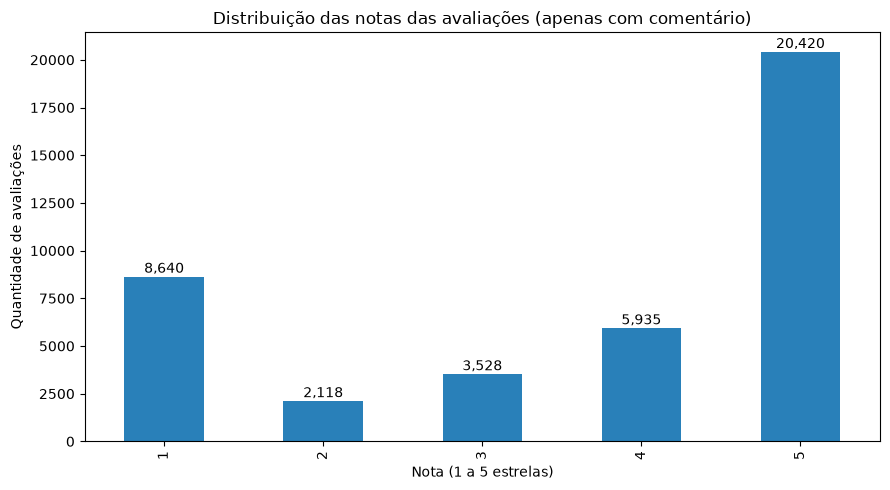

In [6]:
contagem_notas = base["review_score"].value_counts().sort_index()
ax = contagem_notas.plot(kind="bar", color="#2980b9")
ax.set_title("Distribuição das notas das avaliações (apenas com comentário)")
ax.set_xlabel("Nota (1 a 5 estrelas)")
ax.set_ylabel("Quantidade de avaliações")
for i, valor in enumerate(contagem_notas):
    ax.text(i, valor + 200, f"{valor:,}", ha="center")
plt.tight_layout()
plt.show()

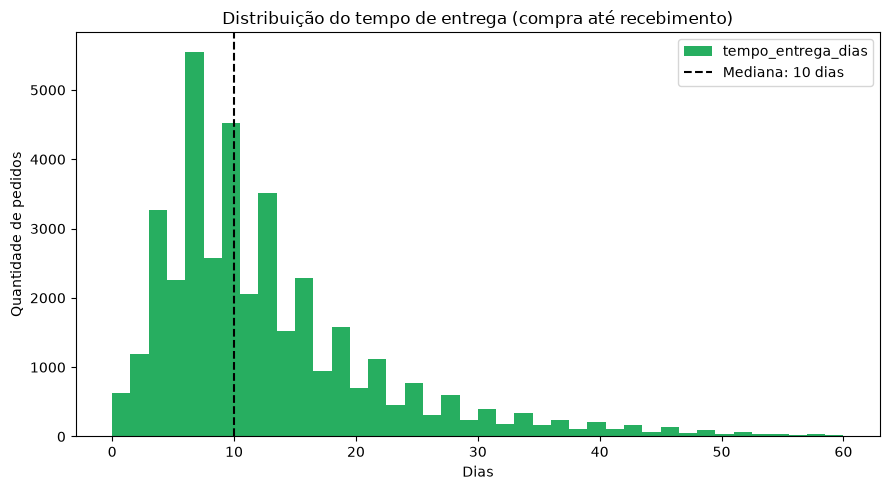

In [7]:
tempo_entrega_valido = base.loc[base["tempo_entrega_dias"].between(0, 60), "tempo_entrega_dias"]

ax = tempo_entrega_valido.plot(kind="hist", bins=40, color="#27ae60")
ax.axvline(tempo_entrega_valido.median(), color="black", linestyle="--", label=f"Mediana: {tempo_entrega_valido.median():.0f} dias")
ax.set_title("Distribuição do tempo de entrega (compra até recebimento)")
ax.set_xlabel("Dias")
ax.set_ylabel("Quantidade de pedidos")
ax.legend()
plt.tight_layout()
plt.show()

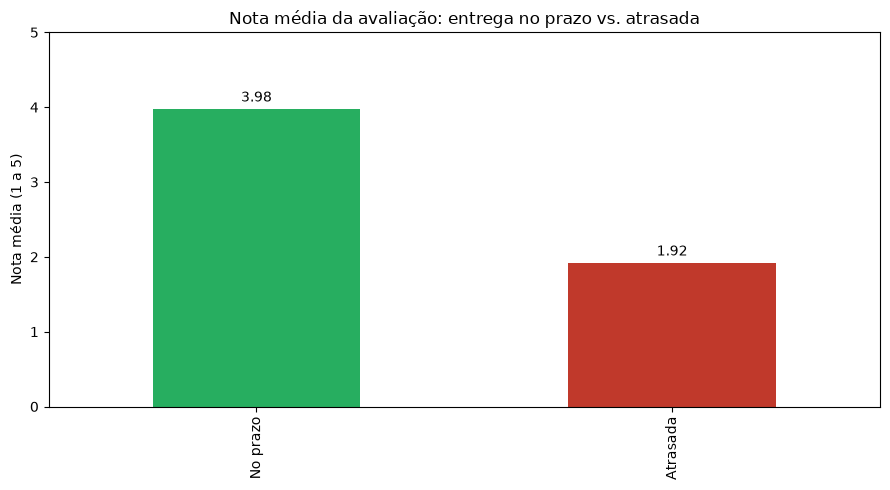

No prazo    3.975206
Atrasada    1.918335
Name: review_score, dtype: float64


In [8]:
nota_media_por_atraso = base.dropna(subset=["entrega_atrasada"]).groupby("entrega_atrasada")["review_score"].mean()
nota_media_por_atraso.index = ["No prazo", "Atrasada"]

ax = nota_media_por_atraso.plot(kind="bar", color=["#27ae60", "#c0392b"])
ax.set_title("Nota média da avaliação: entrega no prazo vs. atrasada")
ax.set_ylabel("Nota média (1 a 5)")
ax.set_xlabel("")
ax.set_ylim(0, 5)
for i, valor in enumerate(nota_media_por_atraso):
    ax.text(i, valor + 0.1, f"{valor:.2f}", ha="center")
plt.tight_layout()
plt.show()

print(nota_media_por_atraso)

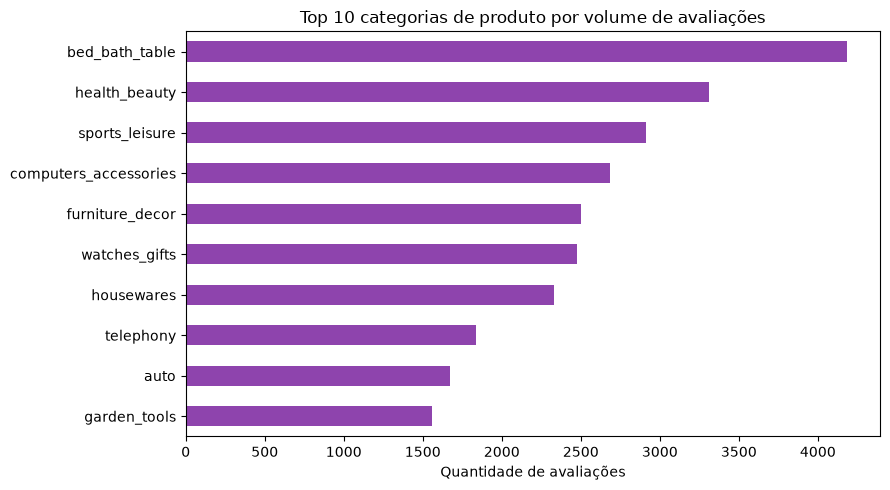

product_category_name_english
computers_accessories    3.52
furniture_decor          3.55
bed_bath_table           3.63
telephony                3.64
watches_gifts            3.68
auto                     3.72
housewares               3.74
sports_leisure           3.74
health_beauty            3.77
garden_tools             3.84
Name: review_score, dtype: float64


In [9]:
top_categorias = base["product_category_name_english"].value_counts().head(10)

ax = top_categorias.sort_values().plot(kind="barh", color="#8e44ad")
ax.set_title("Top 10 categorias de produto por volume de avaliações")
ax.set_xlabel("Quantidade de avaliações")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

nota_media_top_categorias = base[base["product_category_name_english"].isin(top_categorias.index)]
nota_media_top_categorias = nota_media_top_categorias.groupby("product_category_name_english")["review_score"].mean().loc[top_categorias.index]
print(nota_media_top_categorias.round(2).sort_values())

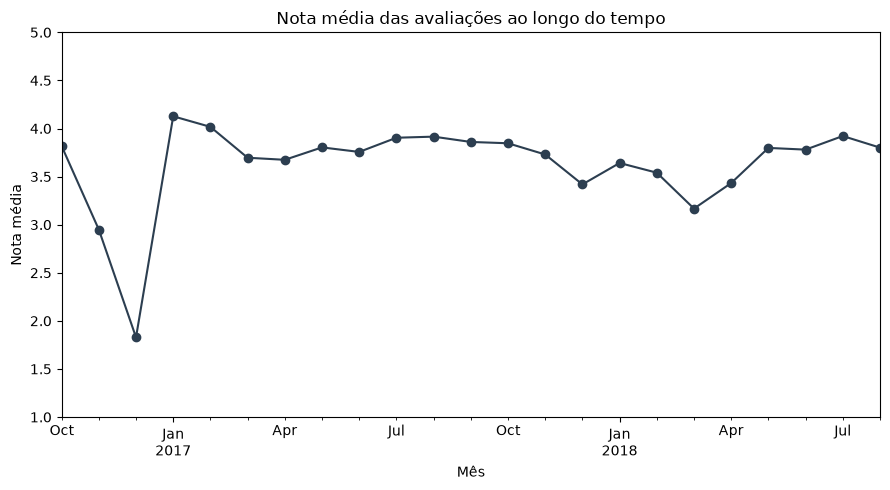

In [10]:
evolucao_mensal = base.set_index("review_creation_date").resample("ME")["review_score"].mean()

ax = evolucao_mensal.plot(kind="line", marker="o", color="#2c3e50")
ax.set_title("Nota média das avaliações ao longo do tempo")
ax.set_xlabel("Mês")
ax.set_ylabel("Nota média")
ax.set_ylim(1, 5)
plt.tight_layout()
plt.show()

## 6. Conclusões

- **Qualidade dos dados**: das 99.224 avaliações, só 41.3% (40.977) têm comentário escrito — é só esse subconjunto que interessa para a busca semântica do RAG. O dataset original também tinha 814 `review_id` duplicados (mesma avaliação ligada a mais de um pedido), removidos na limpeza. Após descartar avaliações sem texto e duplicatas, restaram 40.641 avaliações utilizáveis.
- **Atraso na entrega é o fator com maior impacto na nota**: entre pedidos efetivamente entregues, 10.9% chegaram depois do prazo estimado (4.238 de 38.796). A nota média despenca de **3.98** (entrega no prazo) para **1.92** (entrega atrasada) — o atraso é, de longe, o sinal mais forte de insatisfação no dataset, mais forte que a categoria do produto.
- **Categoria do produto importa pouco isoladamente**: as 10 categorias com mais avaliações (ex: `bed_bath_table` com 4.184, `health_beauty` com 3.312, `sports_leisure` com 2.912) têm nota média em uma faixa estreita (3.52 a 3.84) — nenhuma categoria de alto volume se destaca como excepcionalmente boa ou ruim. Isso sugere que, para o RAG, o metadado `review_score`/atraso é mais informativo como filtro do que a categoria isolada.
- **Implicação para o pipeline RAG**: `entrega_atrasada` e `avaliacao_critica` (criadas aqui como booleanos) são bons candidatos a metadado de filtro no vectorstore (`olist-vectorstore`), já que concentram boa parte do sinal de insatisfação do cliente — reforça a decisão já tomada em `src/data/preprocess.py` de preservar `order_status` e `review_score` junto de cada review indexada.